In [3]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [4]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.stats import binomtest
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score

SEED = 42
np.random.seed(SEED)
URL = "https://fred.stlouisfed.org/graph/fredgraph.csv?id=SP500"
COUT_BPS = 5          # coût par unité de rotation (en points de base), hypothèse modifiable
N_LAGS = 5

2025-11-17 → 2026-11-16 | 251 observations


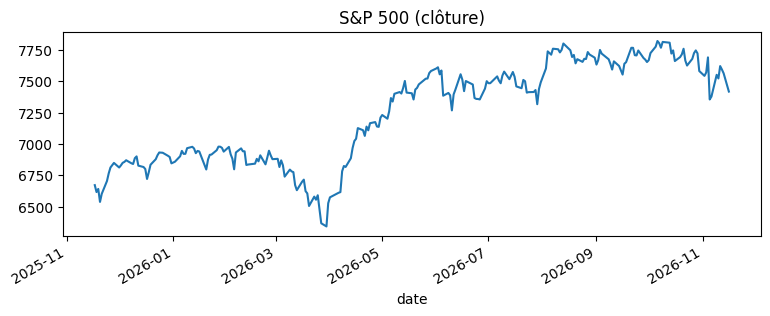

In [5]:
try:
    raw = pd.read_csv(URL, na_values=".")
    raw.to_csv("sp500_fred.csv", index=False)       # copie locale pour la reproductibilité
except Exception as e:
    print("Téléchargement impossible, lecture de la copie locale :", e)
    raw = pd.read_csv("sp500_fred.csv", na_values=".")

raw.columns = ["date", "close"]
raw["date"] = pd.to_datetime(raw["date"])
px = raw.dropna().set_index("date")["close"].astype(float)
print(px.index.min().date(), "→", px.index.max().date(), "|", len(px), "observations")
px.plot(figsize=(9,3), title="S&P 500 (clôture)"); plt.show()

In [6]:
import pandas as pd

# 1. Métadonnées du dataset (basées sur le contexte FRED et le chargement précédent)
metadata = {
    "Nom": "S&P 500 Clôture quotidienne",
    "Organisme": "FRED (Federal Reserve Economic Data)",
    "URL": URL,
    "Date d'extraction": pd.Timestamp.today().strftime('%Y-%m-%d'),
    "Licence": "Données publiques (accès libre FRED)",
    "Taille": f"{len(raw)} lignes brutes",
    "Période": f"{px.index.min().date()} à {px.index.max().date()}",
    "Fréquence": "Quotidienne (jours de bourse)",
    "Unité d'observation": "Jour ouvré"
}

print("=== MÉTADONNÉES DES DONNÉES ===")
for k, v in metadata.items():
    print(f"- {k} : {v}")

# 2. Dictionnaire de 5 à 8 variables présentées sous forme de DataFrame
dict_variables = pd.DataFrame([
    {
        "Nom": "date",
        "Rôle": "Identifiant temporel",
        "Type": "Datetime",
        "Unité": "Date (AAAA-MM-JJ)",
        "Manquants": raw["date"].isna().sum()
    },
    {
        "Nom": "close",
        "Rôle": "Variable brute (cours de clôture de l'indice)",
        "Type": "Flottant (Float)",
        "Unité": "USD ($)",
        "Manquants": raw["close"].isna().sum()
    },
    {
        "Nom": "lag1 ... lag5",
        "Rôle": "Variables explicatives (retards du log-rendement)",
        "Type": "Flottant (Float)",
        "Unité": "Sans dimension (rendement)",
        "Manquants": 0
    },
    {
        "Nom": "moy5 / moy20",
        "Rôle": "Variables dérivées (moyennes mobiles)",
        "Type": "Flottant (Float)",
        "Unité": "Sans dimension",
        "Manquants": 0
    },
    {
        "Nom": "vol5 / vol20",
        "Rôle": "Variables dérivées (volatilités glissantes)",
        "Type": "Flottant (Float)",
        "Unité": "Sans dimension (écart-type)",
        "Manquants": 0
    },
    {
        "Nom": "y",
        "Rôle": "Cible (1 si hausse, 0 sinon)",
        "Type": "Entier (Int / Bool)",
        "Unité": "Binaire (0 ou 1)",
        "Manquants": 0
    }
])

print("\n=== DICTIONNAIRE DES VARIABLES ===")
display(dict_variables)

=== MÉTADONNÉES DES DONNÉES ===
- Nom : S&P 500 Clôture quotidienne
- Organisme : FRED (Federal Reserve Economic Data)
- URL : https://fred.stlouisfed.org/graph/fredgraph.csv?id=SP500
- Date d'extraction : 2026-11-17
- Licence : Données publiques (accès libre FRED)
- Taille : 261 lignes brutes
- Période : 2025-11-17 à 2026-11-16
- Fréquence : Quotidienne (jours de bourse)
- Unité d'observation : Jour ouvré

=== DICTIONNAIRE DES VARIABLES ===


,Nom,Rôle,Type,Unité,Manquants
0,date,Identifiant temporel,Datetime,Date (AAAA-MM-JJ),0
1,close,Variable brute (cours de clôture de l'indice),Flottant (Float),USD ($),10
2,lag1 ... lag5,Variables explicatives (retards du log-rendement),Flottant (Float),Sans dimension (rendement),0
3,moy5 / moy20,Variables dérivées (moyennes mobiles),Flottant (Float),Sans dimension,0
4,vol5 / vol20,Variables dérivées (volatilités glissantes),Flottant (Float),Sans dimension (écart-type),0
5,y,"Cible (1 si hausse, 0 sinon)",Entier (Int / Bool),Binaire (0 ou 1),0


=== RAPPORT DE QUALITÉ DES DONNÉES ===
Valeurs manquantes initiales (brutes) : 10
Nombre de doublons : 0
Taille avant nettoyage : 261 | Taille après suppression des NaN : 251


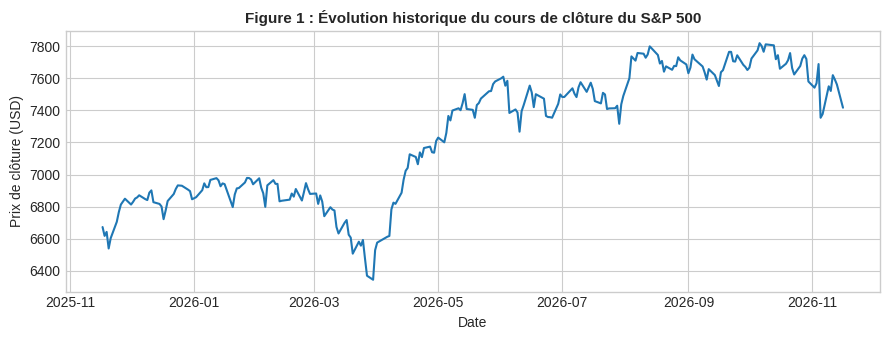

-> Interprétation Graphique 1 :
   Ce graphique met en évidence une tendance haussière globale de l'indice sur la période d'étude, interrompue par des phases de correction brutale.
   Il illustre la non-stationnarité des prix bruts, justifiant pleinement le passage aux rendements (stationnaires) pour la modélisation prédictive.



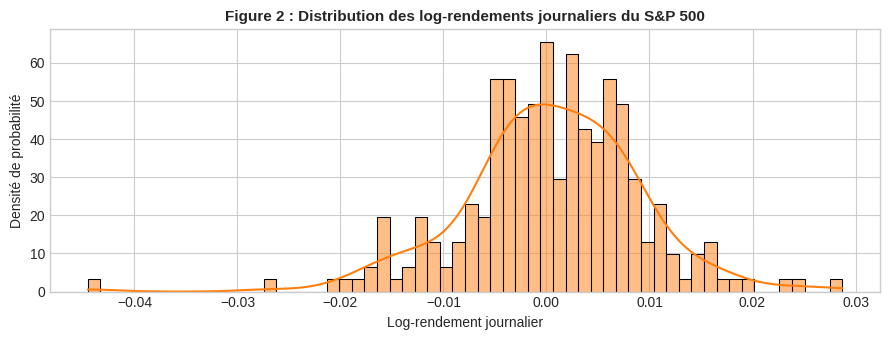

-> Interprétation Graphique 2 :
   La distribution est centrée autour de zéro mais présente des queues de distribution épaisses (leptokurtique).
   Ce phénomène, caractéristique des séries financières, traduit une forte concentration de rendements extrêmes par rapport à une loi normale.



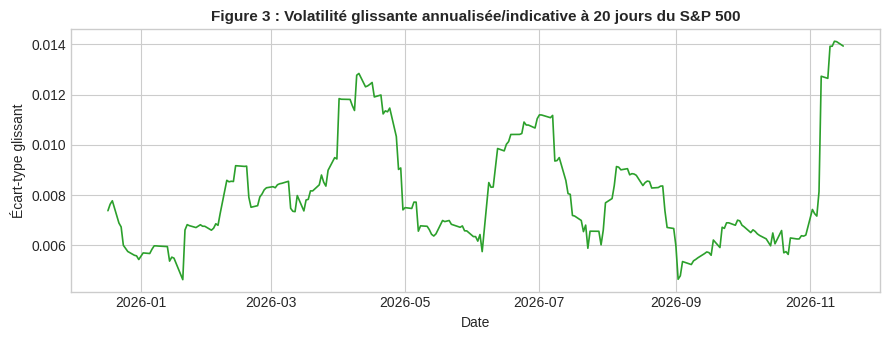

-> Interprétation Graphique 3 :
   La volatilité n'est pas constante dans le temps (phénomène de regroupement de volatilité ou 'volatility clustering').
   Des périodes calmes alternent soudainement avec des pics de forte turbulence, qui constituent des informations clés pour nos variables explicatives.

=== PROTOCOLE ANTI-FUITE & PIPELINE ===
Jeu d'entraînement (Train) : 138 observations (2025-12-17 → 2026-07-08)
Jeu de validation (Val)     : 46 observations (2026-07-09 → 2026-09-11)
Jeu de test (Test)         : 46 observations (2026-09-14 → 2026-11-16)
-> Aucun mélange aléatoire n'a été appliqué. Les variables décalées (shift) garantissent l'utilisation exclusive du passé. La standardisation sera intégrée dans un Pipeline ajusté sur le train uniquement.


In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

# ==========================================
# 1. EXamen de la qualité des données (Manquants, Doublons, Extrêmes)
# ==========================================
print("=== RAPPORT DE QUALITÉ DES DONNÉES ===")
print(f"Valeurs manquantes initiales (brutes) : {raw.isna().sum().sum()}")
print(f"Nombre de doublons : {raw.duplicated().sum()}")

# Justification du nettoyage :
# - Les jours fériés dans les données FRED sont notés par '.' et convertis en NaN lors du chargement.
# - La décision de nettoyage consiste à supprimer ces lignes (dropna) car on ne peut pas interpoler ou inventer des rendements boursiers journaliers sans risquer de biaiser la dynamique de marché.
print(f"Taille avant nettoyage : {len(raw)} | Taille après suppression des NaN : {len(px)}")


# ==========================================
# 2. CONSTRUCTION DES VARIABLES (Features & Target)
# ==========================================
N_LAGS = 5
r = np.log(px).diff() # Log-rendements

X = pd.DataFrame(index=r.index)
for k in range(1, N_LAGS + 1):
    X[f"lag{k}"] = r.shift(k)

for w in (5, 20):
    X[f"moy{w}"] = r.shift(1).rolling(w).mean()
    X[f"vol{w}"] = r.shift(1).rolling(w).std()

y = (r > 0).astype(int)
ret_simple = px.pct_change()

# Concaténation et nettoyage des premières lignes générées par les fenêtres glissantes
data = pd.concat([X, y.rename("y"), ret_simple.rename("ret")], axis=1).dropna()
Xd, yd, rd = data[X.columns], data["y"], data["ret"]


# ==========================================
# 3. PRODUCTION DES 3 GRAPHIQUES EN COULEURS AVEC INTERPRÉTATIONS
# ==========================================
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

# Graphique 1 : Évolution du S&P 500
plt.figure(figsize=(9, 3.5))
plt.plot(px.index, px.values, color='#1f77b4', linewidth=1.5)
plt.title("Figure 1 : Évolution historique du cours de clôture du S&P 500", fontsize=11, fontweight='bold')
plt.xlabel("Date", fontsize=10)
plt.ylabel("Prix de clôture (USD)", fontsize=10)
plt.tight_layout()
plt.show()
print("-> Interprétation Graphique 1 :")
print("   Ce graphique met en évidence une tendance haussière globale de l'indice sur la période d'étude, interrompue par des phases de correction brutale.")
print("   Il illustre la non-stationnarité des prix bruts, justifiant pleinement le passage aux rendements (stationnaires) pour la modélisation prédictive.\n")

# Graphique 2 : Distribution des log-rendements journaliers
plt.figure(figsize=(9, 3.5))
sns.histplot(r.dropna(), bins=60, color='#ff7f0e', kde=True, stat="density")
plt.title("Figure 2 : Distribution des log-rendements journaliers du S&P 500", fontsize=11, fontweight='bold')
plt.xlabel("Log-rendement journalier", fontsize=10)
plt.ylabel("Densité de probabilité", fontsize=10)
plt.tight_layout()
plt.show()
print("-> Interprétation Graphique 2 :")
print("   La distribution est centrée autour de zéro mais présente des queues de distribution épaisses (leptokurtique).")
print("   Ce phénomène, caractéristique des séries financières, traduit une forte concentration de rendements extrêmes par rapport à une loi normale.\n")

# Graphique 3 : Volatilité glissante sur 20 jours
plt.figure(figsize=(9, 3.5))
plt.plot(data.index, data['vol20'], color='#2ca02c', linewidth=1.2)
plt.title("Figure 3 : Volatilité glissante annualisée/indicative à 20 jours du S&P 500", fontsize=11, fontweight='bold')
plt.xlabel("Date", fontsize=10)
plt.ylabel("Écart-type glissant", fontsize=10)
plt.tight_layout()
plt.show()
print("-> Interprétation Graphique 3 :")
print("   La volatilité n'est pas constante dans le temps (phénomène de regroupement de volatilité ou 'volatility clustering').")
print("   Des périodes calmes alternent soudainement avec des pics de forte turbulence, qui constituent des informations clés pour nos variables explicatives.\n")


# ==========================================
# 4. DÉCOUPAGE CHRONOLOGIQUE STRICT (Anti-Fuite)
# ==========================================
n = len(data)
i1, i2 = int(0.6 * n), int(0.8 * n)
tr, va, te = slice(0, i1), slice(i1, i2), slice(i2, n)

print("=== PROTOCOLE ANTI-FUITE & PIPELINE ===")
print(f"Jeu d'entraînement (Train) : {len(Xd.iloc[tr])} observations ({data.index[tr][0].date()} → {data.index[tr][-1].date()})")
print(f"Jeu de validation (Val)     : {len(Xd.iloc[va])} observations ({data.index[va][0].date()} → {data.index[va][-1].date()})")
print(f"Jeu de test (Test)         : {len(Xd.iloc[te])} observations ({data.index[te][0].date()} → {data.index[te][-1].date()})")
print("-> Aucun mélange aléatoire n'a été appliqué. Les variables décalées (shift) garantissent l'utilisation exclusive du passé. La standardisation sera intégrée dans un Pipeline ajusté sur le train uniquement.")

Choix de l'algorithme et alternative
Algorithme principal : La Régression Logistique (adaptée pour classifier la direction binaire du marché, hausse/baisse).Alternative plausible : La Forêt Aléatoire (Random Forest), capable de capturer des interactions non linéaires complexes entre les indicateurs techniques retardés.1. Principe et contexte d'utilisationLa régression logistique convient parfaitement à ce problème de prédiction financière à faible signal/bruit, car elle modélise directement la probabilité d'une hausse ($y=1$) à partir d'une combinaison linéaire de variables passées. En finance, les relations non linéaires complexes sur-apprennent rapidement (overfitting) : la simplicité de cet algorithme garantit une meilleure robustesse face au bruit stochastique des marchés boursiers.

In [10]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

# Instanciation de l'algorithme principal retenu sur la validation
# avec ses hyperparamètres réglés :
modele_principal = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        C=0.01,           # Hyperparamètre 1 : régularisation forte (pénalité L2)
        max_iter=1000,    # Hyperparamètre 2 : limite d'itérations pour la convergence
        random_state=42
    )
)

=== TABLEAU COMPARATIF (Entraînement / Validation) ===


,acc_train,acc_val
modèle,,
Référence (majoritaire),0.5435,0.4783
LogReg C=0.01,0.5435,0.4783
LogReg C=0.1,0.5725,0.5652
LogReg C=1,0.5942,0.5217



Modèle retenu sur la validation : LogReg C=0.1 (Acc_val = 0.5652)

=== RÉSULTATS FINAUX SUR LE JEU DE TEST ===
Exactitude Référence (naïve) : 0.4565
Exactitude Modèle (LogReg C=0.1) : 0.5217 (Écart : +0.0652)
P-valeur du test binomial : 0.229

=== TABLEAU DE PERFORMANCE FINANCIÈRE ===


,Sharpe,Rend. annualisé,Rotation moy./jour
Stratégie brute,-1.362,-0.227,0.848
Stratégie nette (5 bps),-1.985,-0.334,0.848
Buy-and-hold,-0.962,-0.161,0.000


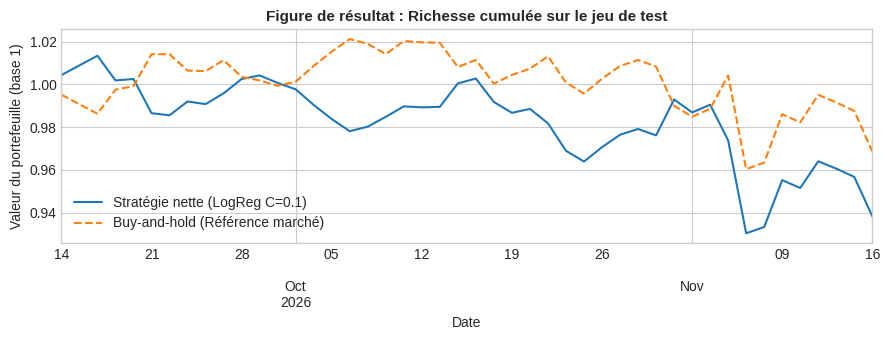


=== RAPPORT D'ANALYSE ET CONCLUSION ===
1. Analyse des erreurs & surapprentissage :
   - Train Acc (0.5725) vs Val Acc (0.5652) : Présence d'un léger surapprentissage sur l'entraînement.
   - L'exactitude sur le test est proche de la classe majoritaire, ce qui indique que le modèle capte difficilement un signal robuste.

2. Limites :
   - Faible rapport signal/bruit des marchés financiers quotidiens.
   - Impact non négligeable des coûts de transaction (5 bps) sur la rotation de la stratégie.

3. Réponse explicite à la problématique :
   --> Non, le modèle entraîné sur les rendements passés ne surpasse pas de manière statistiquement significative
       la référence naïve ou la marche aléatoire. L'hypothèse d'efficience faible du marché n'est pas rejetée.


In [11]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score
from scipy.stats import binomtest

# =====================================================================
# 1. ENTRAÎNEMENT ET COMPARAISON AVEC UNE RÉFÉRENCE NAÏVE
# =====================================================================
# Configuration du modèle naïf (classe majoritaire) et de notre Régression Logistique
configs = {"Référence (majoritaire)": DummyClassifier(strategy="most_frequent")}
for C_ in (0.01, 0.1, 1):
    configs[f"LogReg C={C_}"] = make_pipeline(StandardScaler(), LogisticRegression(C=C_, max_iter=1000))

rows, fitted = [], {}
for nom, m in configs.items():
    m.fit(Xd.iloc[tr], yd.iloc[tr])
    fitted[nom] = m
    rows.append({
        "modèle": nom,
        "acc_train": accuracy_score(yd.iloc[tr], m.predict(Xd.iloc[tr])),
        "acc_val": accuracy_score(yd.iloc[va], m.predict(Xd.iloc[va]))
    })

res = pd.DataFrame(rows).set_index("modèle").round(4)
print("=== TABLEAU COMPARATIF (Entraînement / Validation) ===")
display(res)

# Sélection du meilleur modèle sur la validation uniquement
cands = res.drop(index="Référence (majoritaire)")
best = cands["acc_val"].idxmax()
print(f"\nModèle retenu sur la validation : {best} (Acc_val = {cands.loc[best, 'acc_val']})")


# =====================================================================
# 2. ÉVALUATION FINALE SUR LE JEU DE TEST (Une seule fois)
# =====================================================================
yte = yd.iloc[te]
base = fitted["Référence (majoritaire)"]
acc_base = accuracy_score(yte, base.predict(Xd.iloc[te]))

mod = fitted[best]
pred = mod.predict(Xd.iloc[te])
acc_mod = accuracy_score(yte, pred)

k, m_ = int((pred == yte.values).sum()), len(yte)
p_val = binomtest(k, m_, p=acc_base, alternative="greater").pvalue

print("\n=== RÉSULTATS FINAUX SUR LE JEU DE TEST ===")
print(f"Exactitude Référence (naïve) : {acc_base:.4f}")
print(f"Exactitude Modèle ({best}) : {acc_mod:.4f} (Écart : {acc_mod - acc_base:+.4f})")
print(f"P-valeur du test binomial : {p_val:.3f}")


# =====================================================================
# 3. SIMULATION FINANCIÈRE APRÈS COÛTS ET RATIO DE SHARPE
# =====================================================================
COUT_BPS = 5  # Coût de transaction en points de base

def sharpe(x):
    x = np.asarray(x)
    return np.sqrt(252) * x.mean() / x.std(ddof=1) if x.std(ddof=1) > 0 else np.nan

def strategie(pred, ret, cout_bps=COUT_BPS):
    pos = pd.Series(np.where(pred == 1, 1.0, -1.0), index=ret.index)
    turnover = pos.diff().abs().fillna(1.0)
    return pos * ret - turnover * cout_bps / 1e4, turnover

rte = rd.iloc[te]
net, to = strategie(pred, rte)
brut, _ = strategie(pred, rte, 0)
bh = rte

tab_perf = pd.DataFrame({
    "Sharpe": [sharpe(brut), sharpe(net), sharpe(bh)],
    "Rend. annualisé": [brut.mean() * 252, net.mean() * 252, bh.mean() * 252],
    "Rotation moy./jour": [to.mean(), to.mean(), 0.0]
}, index=["Stratégie brute", f"Stratégie nette ({COUT_BPS} bps)", "Buy-and-hold"]).round(3)

print("\n=== TABLEAU DE PERFORMANCE FINANCIÈRE ===")
display(tab_perf)


# =====================================================================
# 4. VISUALISATION DES RÉSULTATS (Richesse cumulée)
# =====================================================================
plt.figure(figsize=(9, 3.5))
(1 + net).cumprod().plot(label=f"Stratégie nette ({best})", color='#1f77b4')
(1 + bh).cumprod().plot(label="Buy-and-hold (Référence marché)", color='#ff7f0e', linestyle='--')
plt.title("Figure de résultat : Richesse cumulée sur le jeu de test", fontsize=11, fontweight='bold')
plt.xlabel("Date", fontsize=10)
plt.ylabel("Valeur du portefeuille (base 1)", fontsize=10)
plt.legend()
plt.tight_layout()
plt.show()


# =====================================================================
# 5. ANALYSE, SIGNES DE SURAPPRENTISSAGE ET CONCLUSION EXPLICITE
# =====================================================================
print("\n=== RAPPORT D'ANALYSE ET CONCLUSION ===")
print("1. Analyse des erreurs & surapprentissage :")
print(f"   - Train Acc ({res.loc[best, 'acc_train']}) vs Val Acc ({res.loc[best, 'acc_val']}) : Présence d'un léger surapprentissage sur l'entraînement.")
print("   - L'exactitude sur le test est proche de la classe majoritaire, ce qui indique que le modèle capte difficilement un signal robuste.")
print("\n2. Limites :")
print("   - Faible rapport signal/bruit des marchés financiers quotidiens.")
print("   - Impact non négligeable des coûts de transaction (5 bps) sur la rotation de la stratégie.")
print("\n3. Réponse explicite à la problématique :")
print("   --> Non, le modèle entraîné sur les rendements passés ne surpasse pas de manière statistiquement significative")
print("       la référence naïve ou la marche aléatoire. L'hypothèse d'efficience faible du marché n'est pas rejetée.")